# Risk Analytics Workbench — Meridian Target Retirement Series
Fund-level risk, risk decomposition, factor risk and its history, stress tests (historical and hypothetical, normal to extreme), and look-through exposures. Everything here calls the same deterministic code as the console (`meridian.analytics.risk`), so the numbers tie out.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from meridian.analytics import risk as RK
from meridian.analytics.positioning import Taxonomy
from meridian.data import DataRegistry, Request, to_wide_returns
from meridian.policy import load_policy, load_universe
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pol, uni = load_policy(), load_universe(); assets = pol.assets; ul = [uni[a] for a in assets]
reg = DataRegistry.from_config(); AS_OF = '2026-10-31'

## 1. Data and the risk model
Returns, fund characteristics (durations) and look-through holdings come from whatever sources are plugged in (`config/data_sources.yaml`). The risk model settings, factors and scenarios live in `config/risk.yaml`.

In [2]:
rets = to_wide_returns(reg.get(Request('returns.monthly', ul, start='1999-01-31', end=AS_OF)).frame, assets)
cfg = RK.load_risk_config()
chars = reg.get(Request('fund.characteristics', ul, as_of=AS_OF)).frame
try:
    hold = reg.get(Request('holdings.lookthrough', ul, as_of=AS_OF)).frame
except Exception as e:
    hold = None; print('No look-through holdings loaded:', e)
ch = RK.characteristics(assets, chars, hold, cfg, uni)
m = RK.risk_model(rets, cfg, ch['eff_duration'])
print(f'Risk model {m.start} → {m.end}, {m.months} months, Ledoit-Wolf shrinkage {m.shrinkage:.2f}')
pd.DataFrame({'eff_duration': ch['eff_duration'], 'spread_duration': ch['spread_duration'], 'source': ch['source']})

Risk model 2002-08-31 → 2026-10-31, 291 months, Ledoit-Wolf shrinkage 0.08


,eff_duration,spread_duration,source
us_large_cap,0.0000,0.0000,cache+manual: Equity — no duration
us_small_mid_cap,0.0000,0.0000,cache+manual: Equity — no duration
intl_developed_eq,0.0000,0.0000,cache+manual: Equity — no duration
emerging_eq,0.0000,0.0000,cache+manual: Equity — no duration
global_reits,0.0000,0.0000,cache+manual: Equity (REITs) — no duration
commodities,0.0000,0.0000,cache+manual: Commodity futures; T-bill collat...
us_core_bond,5.7263,3.1453,"holdings look-through (AGG, 2026-11-05)"
us_long_treasury,14.8892,0.0000,"holdings look-through (TLT, 2026-11-05)"
us_tips_short,2.3833,0.0000,"holdings look-through (STIP, 2026-11-05)"
us_high_yield,3.1581,3.1581,"holdings look-through (HYG, 2026-11-05)"


## 2. Fund-level risk — all vintages
Total risk vs benchmark (the glide path), relative duration, credit spread duration, VaR 95 and active VaR 95 (1-month, parametric), and diversification.

In [3]:
frac = pd.Timestamp(AS_OF).year + (pd.Timestamp(AS_OF).dayofyear - 1) / 365.25
bench = {v: pol.neutral_weights(v - frac) for v in pol.vintages}
# Replace with a run's proposals: json.load(open('runs/<run_id>/results.json'))['vintages'][str(v)]['final']
port = dict(bench)
rows = {v: RK.fund_metrics(port[v], bench[v], m, ch, cfg) for v in pol.vintages}
pd.DataFrame(rows).T[['total_risk','bench_total_risk','active_risk','eff_duration','bench_eff_duration','rel_duration','spread_duration','rel_spread_duration','var','active_var','diversification','bench_diversification']]

,total_risk,bench_total_risk,active_risk,eff_duration,bench_eff_duration,rel_duration,spread_duration,rel_spread_duration,var,active_var,diversification,bench_diversification
2030,0.0836,0.0836,0.0000,2.2068,2.2068,0.0000,0.9039,0.0000,0.0397,0.0000,0.1956,0.1956
2035,0.0962,0.0962,0.0000,2.0878,2.0878,0.0000,0.8214,0.0000,0.0457,0.0000,0.1769,0.1769
2040,0.1108,0.1108,0.0000,1.7691,1.7691,0.0000,0.6865,0.0000,0.0526,0.0000,0.1543,0.1543
2045,0.1212,0.1212,0.0000,1.3907,1.3907,0.0000,0.5298,0.0000,0.0575,0.0000,0.1354,0.1354
2050,0.1288,0.1288,0.0000,1.0414,1.0414,0.0000,0.3780,0.0000,0.0612,0.0000,0.1193,0.1193
2055,0.1325,0.1325,0.0000,0.8761,0.8761,0.0000,0.3050,0.0000,0.0629,0.0000,0.1123,0.1123
2060,0.1340,0.1340,0.0000,0.8169,0.8169,0.0000,0.2775,0.0000,0.0636,0.0000,0.1102,0.1102
2065,0.1354,0.1354,0.0000,0.7577,0.7577,0.0000,0.2500,0.0000,0.0643,0.0000,0.1081,0.1081
2070,0.1359,0.1359,0.0000,0.7360,0.7360,0.0000,0.2399,0.0000,0.0645,0.0000,0.1074,0.1074


## 3. Risk breakdown and weight vs. risk — one vintage

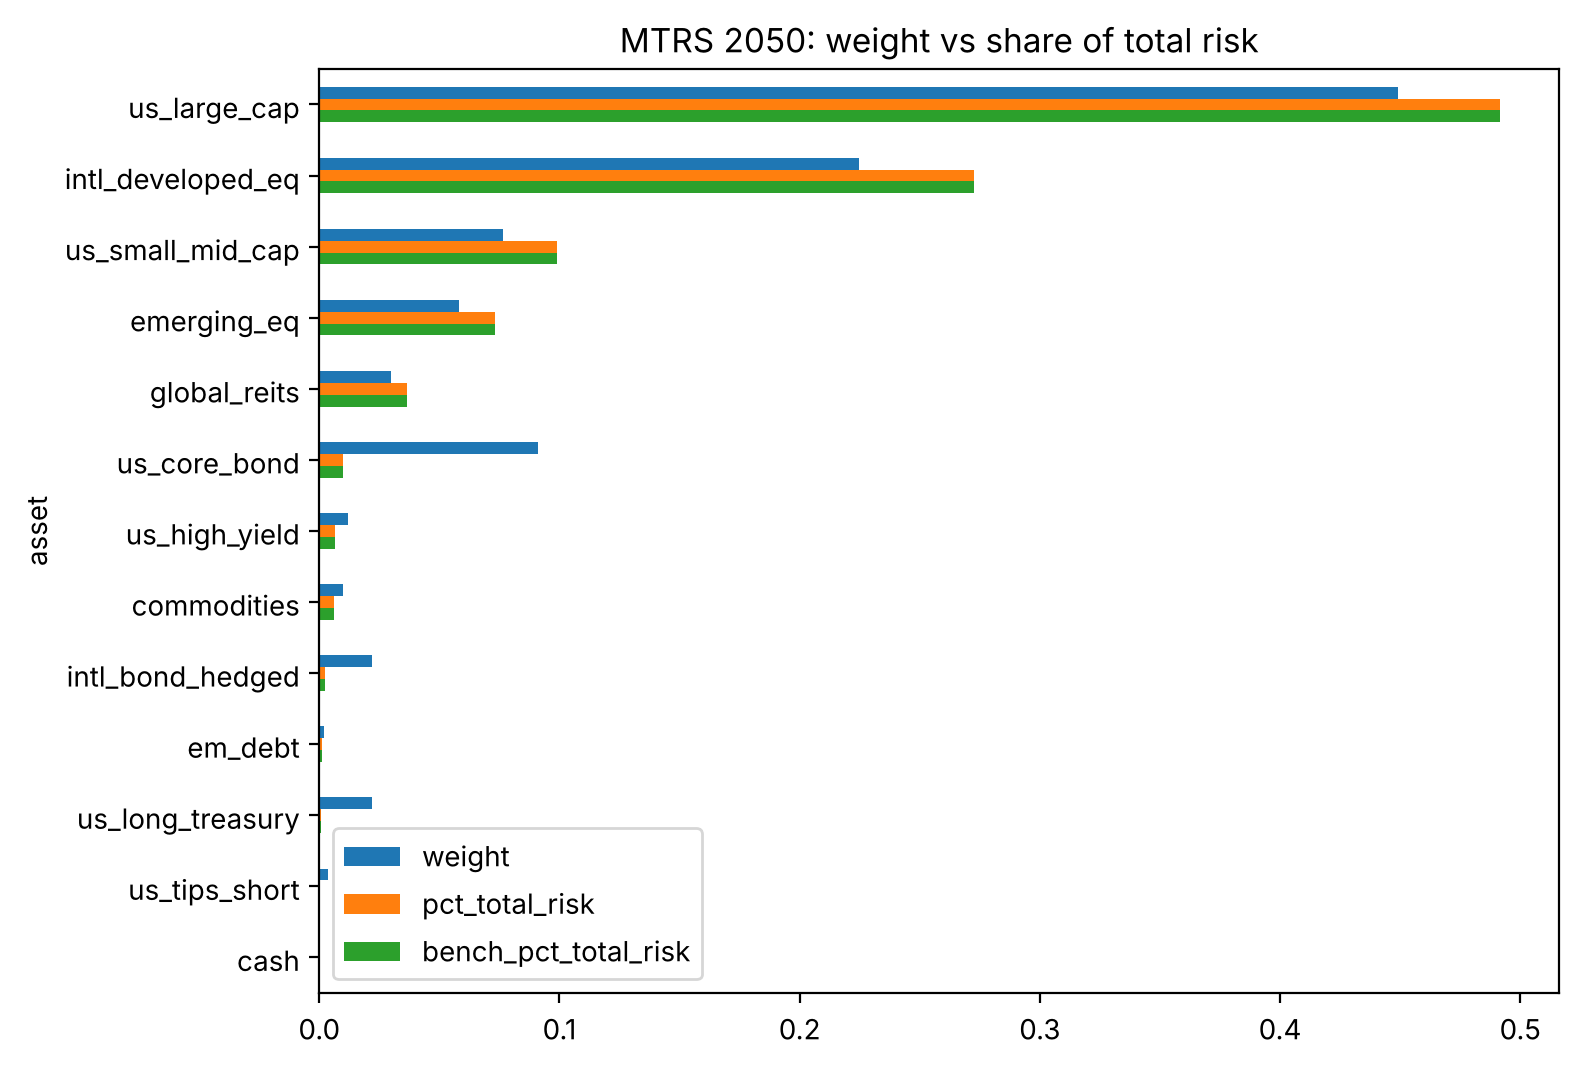

,weight,bench_weight,pct_total_risk,bench_pct_total_risk
node,,,,
Equity,0.8080,0.8080,0.9364,0.9364
Equity/US,0.5254,0.5254,0.5908,0.5908
Equity/US/Large Cap,0.4490,0.4490,0.4917,0.4917
Equity/US/Mid Cap,0.0420,0.0420,0.0545,0.0545
Equity/US/Small Cap,0.0344,0.0344,0.0446,0.0446
Equity/Non-US,0.2827,0.2827,0.3456,0.3456
Equity/Non-US/Developed,0.2245,0.2245,0.2724,0.2724
Equity/Non-US/Developed/Large Cap,0.1908,0.1908,0.2315,0.2315
Equity/Non-US/Developed/Mid Cap,0.0337,0.0337,0.0409,0.0409


In [4]:
V = 2050
bd = RK.risk_breakdown(port[V], bench[V], m, Taxonomy.load(assets))
a = pd.DataFrame(bd['assets']).set_index('asset').sort_values('pct_total_risk', ascending=False)
ax = a[['weight','pct_total_risk','bench_pct_total_risk']].plot.barh(figsize=(8,6)); ax.invert_yaxis(); ax.set_title(f'MTRS {V}: weight vs share of total risk'); plt.show()
pd.DataFrame(bd['nodes']).set_index('node')[['weight','bench_weight','pct_total_risk','bench_pct_total_risk']]

## 4. Factor decomposition

In [5]:
fd = RK.factor_decomposition(port[V], bench[V], m)
pd.DataFrame(fd['total']['factors']).set_index('name')[['family','exposure','factor_vol','pct','contribution']]

,family,exposure,factor_vol,pct,contribution
name,,,,,
Global equity market,Equity,0.8407,0.1483,0.9626,0.1240
Size (US small/mid vs large),Equity,0.0737,0.0933,0.0150,0.0019
Non-US developed vs US,Equity,-0.0453,0.0944,-0.0054,-0.0007
Emerging vs developed equity,Equity,-0.0246,0.1164,-0.0011,-0.0001
US interest rates (duration),Rates,0.0584,0.1190,0.0015,0.0002
Credit spread (high yield),Credit,0.0188,0.0936,0.0100,0.0013
EM sovereign spread,Credit,0.0103,0.0991,0.0057,0.0007
Inflation (breakeven),Inflation,0.0057,0.0423,0.0006,0.0001
Real estate vs equity,Real assets,0.0298,0.1547,0.0035,0.0005


## 5. Factor and risk history (last 18 months)
Each month uses only data available then. Weights come from recorded positions when present, else the glide path for that date.

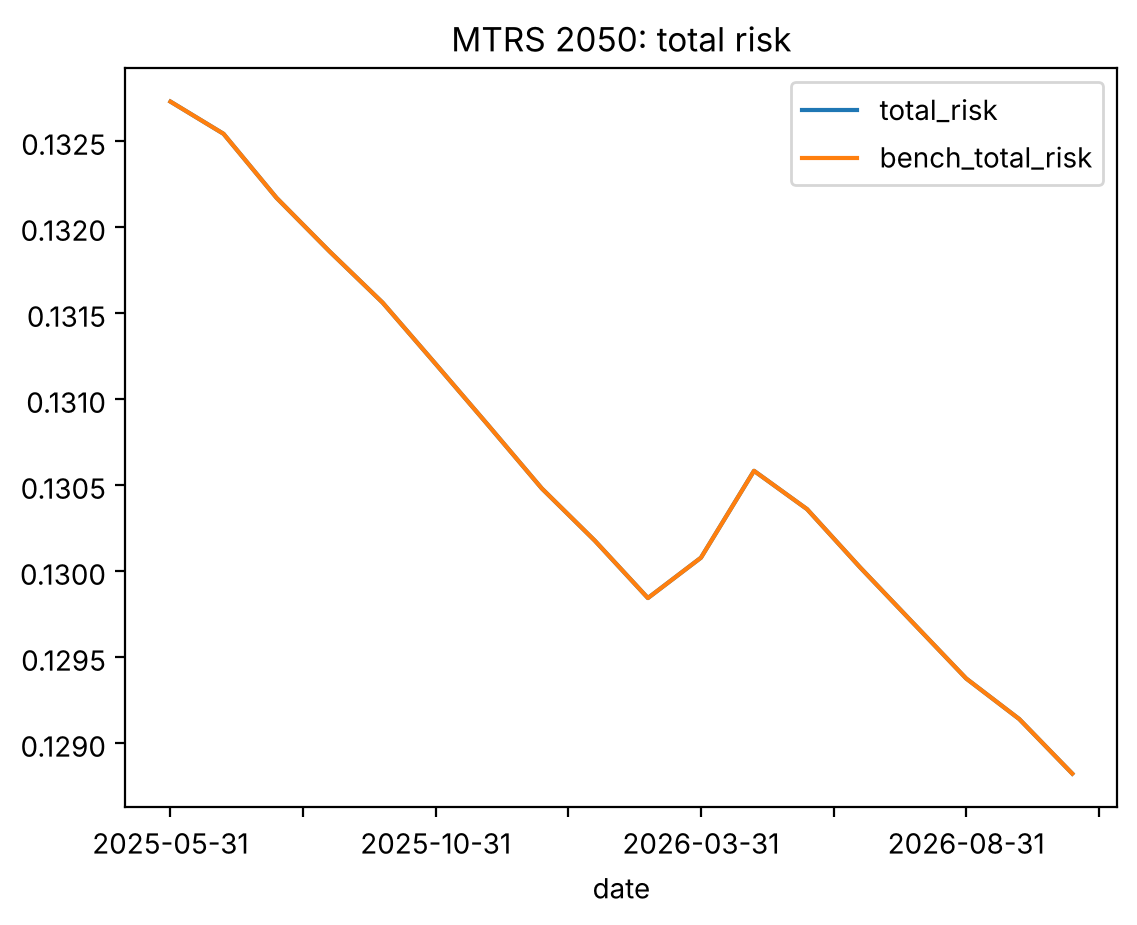

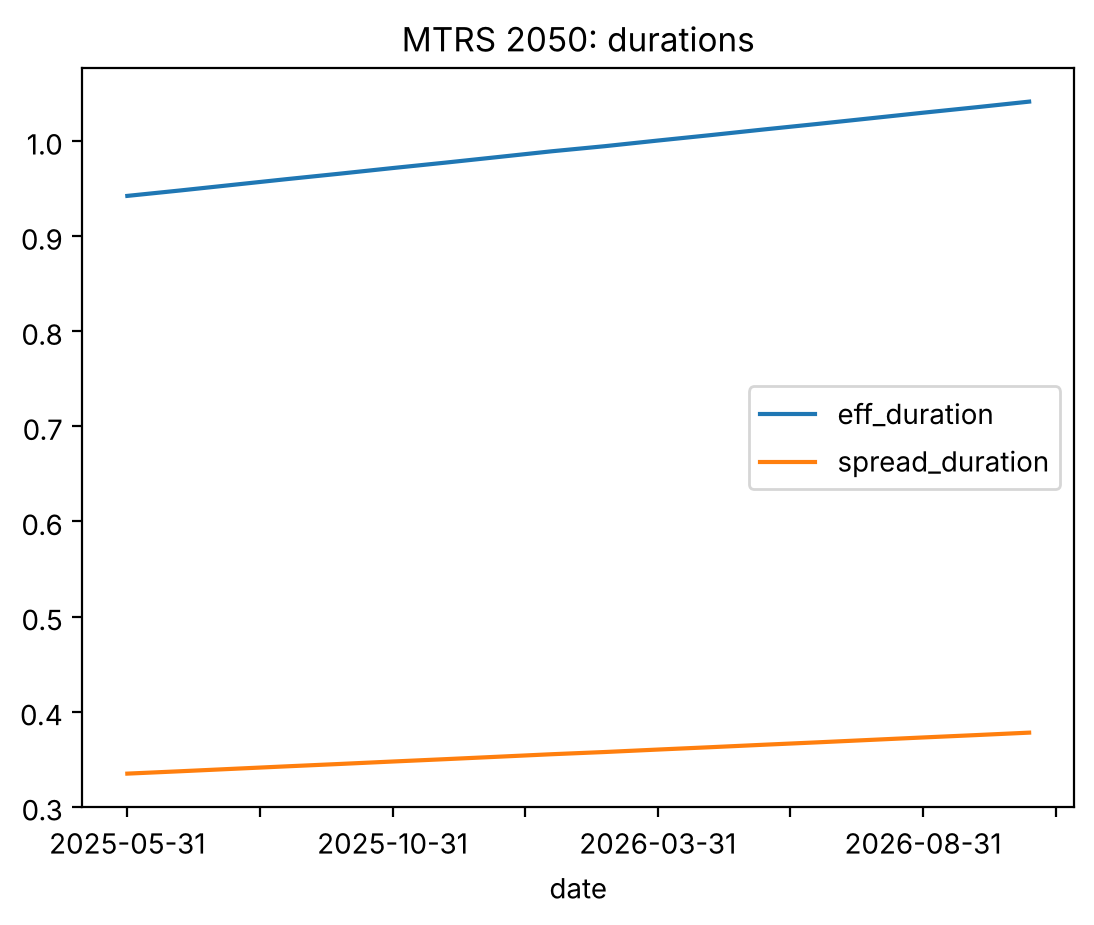

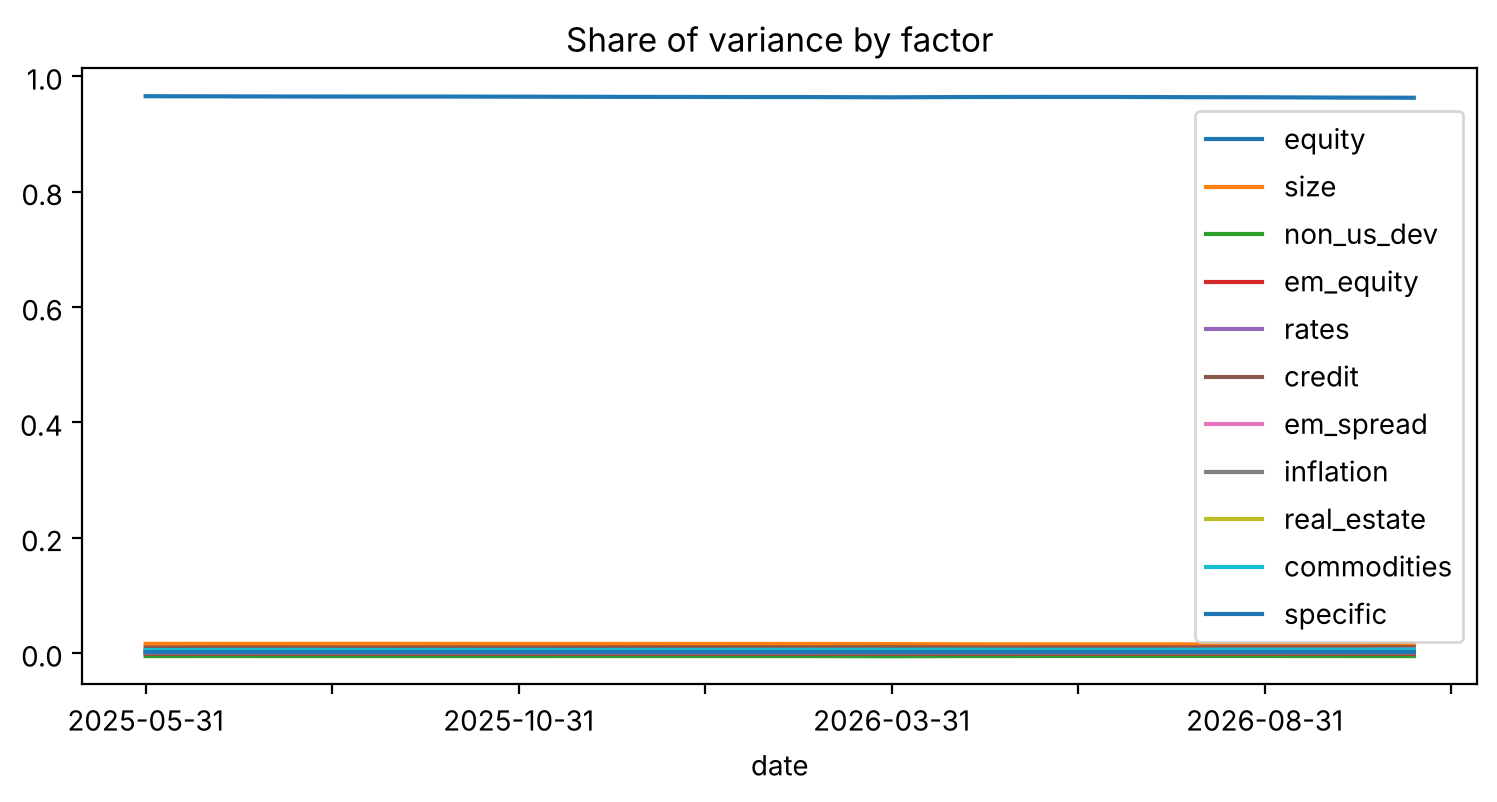

In [6]:
hist = pd.DataFrame(RK.risk_history(rets, cfg, ch, pol, AS_OF, {str(v): port[v] for v in port}, 'notebook'))
h = hist[hist.vintage == V].set_index('date')
h[['total_risk','bench_total_risk']].plot(title=f'MTRS {V}: total risk'); plt.show()
h[['eff_duration','spread_duration']].plot(title=f'MTRS {V}: durations'); plt.show()
pd.DataFrame(list(h['factors']), index=h.index).plot(title='Share of variance by factor', figsize=(9,4)); plt.show()

## 6. Stress tests — historical replays and a severity ladder

In [7]:
st = RK.stress_tests(port, bench, rets, m, cfg)
pd.DataFrame({h['name']: {v: h['vintages'][str(v)]['portfolio'] for v in pol.vintages} for h in st['historical'] if h['available']}).T

,2030,2035,2040,2045,2050,2055,2060,2065,2070
Global financial crisis,-0.2617,-0.3123,-0.3724,-0.4164,-0.4492,-0.4649,-0.4706,-0.4764,-0.4785
Lehman collapse (Sep–Oct 2008),-0.1718,-0.1924,-0.2161,-0.2324,-0.2439,-0.2496,-0.2520,-0.2543,-0.2552
Euro sovereign debt crisis,-0.0789,-0.0988,-0.1236,-0.1431,-0.1584,-0.1657,-0.1683,-0.1709,-0.1718
Taper tantrum,-0.0243,-0.0255,-0.0260,-0.0251,-0.0235,-0.0227,-0.0225,-0.0222,-0.0221
China devaluation & oil slump,-0.0519,-0.0634,-0.0767,-0.0869,-0.0950,-0.0990,-0.1005,-0.1021,-0.1027
Q4 2018 sell-off,-0.0622,-0.0747,-0.0893,-0.1004,-0.1092,-0.1135,-0.1152,-0.1169,-0.1176
COVID-19 crash,-0.1092,-0.1269,-0.1486,-0.1648,-0.1770,-0.1829,-0.1852,-0.1875,-0.1883
2022 inflation & rate shock,-0.1784,-0.1996,-0.2201,-0.2314,-0.2381,-0.2414,-0.2427,-0.2440,-0.2445
Regional bank stress (SVB),0.0240,0.0252,0.0258,0.0258,0.0256,0.0254,0.0253,0.0252,0.0251
2025 tariff shock,-0.0079,-0.0128,-0.0182,-0.0228,-0.0267,-0.0286,-0.0294,-0.0301,-0.0303


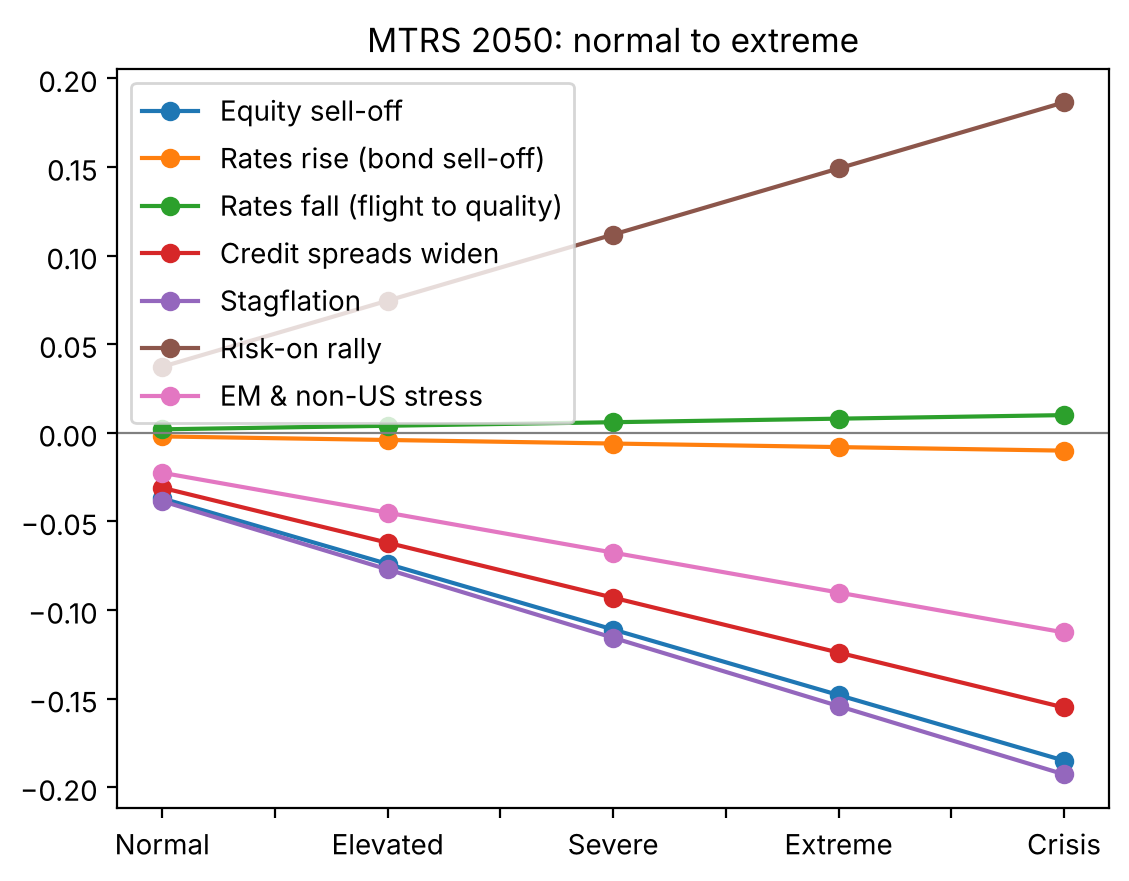

,Equity sell-off,Rates rise (bond sell-off),Rates fall (flight to quality),Credit spreads widen,Stagflation,Risk-on rally,EM & non-US stress
Normal,-0.0370,-0.0020,0.0020,-0.0310,-0.0385,0.0373,-0.0225
Elevated,-0.0740,-0.0040,0.0040,-0.0620,-0.0771,0.0746,-0.0450
Severe,-0.1110,-0.0060,0.0060,-0.0930,-0.1156,0.1119,-0.0676
Extreme,-0.1479,-0.0080,0.0080,-0.1240,-0.1542,0.1492,-0.0901
Crisis,-0.1849,-0.0100,0.0100,-0.1550,-0.1927,0.1865,-0.1126


In [8]:
lad = pd.DataFrame({h['name']: [l['vintages'][str(V)]['portfolio'] for l in h['levels']] for h in st['hypothetical']}, index=[l['label'] for l in st['hypothetical'][0]['levels']])
lad.plot(marker='o', title=f'MTRS {V}: normal to extreme'); plt.axhline(0, color='grey', lw=0.8); plt.show(); lad

### Custom scenario
Shock any factors directly (factor returns, decimals); unset factors follow their correlation (`correlated`) or stay at zero (`isolated`). Rates: −duration × Δyield, e.g. +100bp on long Treasuries ≈ −0.155.

In [9]:
shocks = {'equity': -0.20, 'rates': -ch['eff_duration']['us_long_treasury'] * 0.01}
f = RK.conditional_factor_moves(m, shocks, 'correlated'); r = m.B @ f
pd.Series({v: port[v] @ r for v in pol.vintages}, name='fund return')

2030   -0.1284
2035   -0.1453
2040   -0.1635
2045   -0.1749
2050   -0.1824
2055   -0.1861
2060   -0.1876
2065   -0.1891
2070   -0.1896
Name: fund return, dtype: float64

## 7. Look-through and security search

In [10]:
look = RK.lookthrough(hold, assets, uni, {a: uni[a]['identifiers'].get('proxy_etf','') for a in assets})
if look['available']:
    sec = pd.DataFrame(look['securities'], columns=['ticker','name','sector','asset_class','country'])
    def exposure(ticker):
        idx = sec.index[sec.ticker.str.upper() == ticker.upper()]
        out = {}
        for v in pol.vintages:
            out[v] = sum(port[v][assets.index(a)] * w for a, f in look['funds'].items() for s, w, _ in f['holdings'] if s in idx)
        return pd.Series(out, name=f'{ticker} look-through exposure')
    display(exposure('AAPL'))
else:
    print(look['note'])

2030   0.0226
2035   0.0263
2040   0.0302
2045   0.0332
2050   0.0356
2055   0.0366
2060   0.0369
2065   0.0371
2070   0.0372
Name: AAPL look-through exposure, dtype: float64